# 03 - Preprocessing

Splits the data by patient, cleans implausible values, imputes missing values without leakage and builds features that only use past information. Output: `train.pkl`, `validation.pkl`, `test.pkl` in `data/processed/`.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

PROCESSED_DIR = Path("../data/processed")  # pickles live here (created by the notebooks)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
df = pd.read_pickle(PROCESSED_DIR / "DataFrame.pkl")

## 1. Patient-level split
70 / 15 / 15, stratified by sepsis status. The split is done on patient IDs, so no patient appears in two sets.

In [ ]:
patients = df.groupby("patient_id")[["hospital", "SepsisLabel"]].max()
patients_train, patients_test_ = train_test_split(patients, test_size=0.3, random_state=42, stratify=patients["SepsisLabel"])
patients_test, patients_validation = train_test_split(patients_test_, test_size=0.5, random_state=42, stratify=patients_test_["SepsisLabel"])
train = df[df["patient_id"].isin(patients_train.index)].copy()
test = df[df["patient_id"].isin(patients_test.index)].copy()
validation = df[df["patient_id"].isin(patients_validation.index)].copy()

## 2. Implausible values
Min/max on the training set, then plausible clinical bounds per variable. Values outside the bounds are set to NaN, not dropped, to keep each patient's time series intact.

In [ ]:
display(train.max(axis=0).reset_index().T)
display(train.min(axis=0).reset_index().T)

,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
index,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,patient_id,hospital
0,223.0,100.0,50.0,299.0,300.0,300.0,100.0,100.0,49.5,55.0,...,2322.0,100.0,1,1.0,1.0,23.99,336,1,p120000,B


,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
index,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,patient_id,hospital
0,20.0,20.0,20.9,20.0,20.0,20.0,1.0,10.0,-30.0,5.0,...,1.0,14.0,0,0.0,0.0,-3397.64,1,0,p000001,A


In [ ]:
bounds = {
    "HR": (20, 250), "O2Sat": (50, 100), "Temp": (30, 43),
    "SBP": (40, 260), "MAP": (30, 200), "DBP": (20, 150),
    "Resp": (4, 60), "EtCO2": (10, 80), "BaseExcess": (-30, 30),
    "HCO3": (5, 55), "FiO2": (0, 1), "pH": (6.8, 7.8),
    "PaCO2": (10, 150), "SaO2": (50, 100), "AST": (1, 10000),
    "BUN": (1, 300), "Alkalinephos": (10, 2000), "Calcium": (4, 20),
    "Chloride": (60, 140), "Creatinine": (0.1, 30),
    "Bilirubin_direct": (0, 30), "Glucose": (20, 1000),
    "Lactate": (0.1, 30), "Magnesium": (0.5, 6), "Phosphate": (0.5, 15),
    "Potassium": (1.5, 9), "Bilirubin_total": (0.1, 50),
    "TroponinI": (0, 300), "Hct": (10, 65), "Hgb": (3, 25),
    "PTT": (15, 250), "WBC": (0.1, 200), "Fibrinogen": (20, 1000),
    "Platelets": (1, 1500),
}
for series_name in list(bounds.keys()): 
    print (f"{series_name} : {len(train[(train[series_name] < bounds[series_name][0]) | (train[series_name] > bounds[series_name][1])].index)}")

HR : 0
O2Sat : 166
Temp : 16
SBP : 90
MAP : 459
DBP : 245
Resp : 1382
EtCO2 : 45
BaseExcess : 3
HCO3 : 0
FiO2 : 24
pH : 9
PaCO2 : 0
SaO2 : 196
AST : 0
BUN : 0
Alkalinephos : 10
Calcium : 6947
Chloride : 2
Creatinine : 1
Bilirubin_direct : 1
Glucose : 6
Lactate : 1
Magnesium : 32
Phosphate : 15
Potassium : 54
Bilirubin_total : 0
TroponinI : 0
Hct : 4
Hgb : 5
PTT : 1
WBC : 14
Fibrinogen : 9
Platelets : 2


`Calcium` has 6,947 values below 4. The histogram shows a second cluster around 1 mmol/L (ionised calcium), so the lower bound is relaxed to 0.5 instead of discarding them.

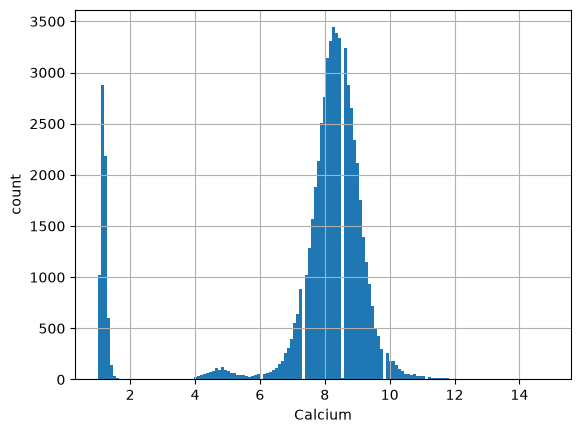

In [ ]:
ca = train["Calcium"].dropna()
ca[ca < 15].hist(bins=150)
plt.xlabel("Calcium")
plt.ylabel("count")
plt.show()

In [ ]:
len(train[(train["Calcium"] < 0.5) | (train["Calcium"] > 20)].index)

8

Apply the bounds to all three sets.

In [ ]:
bounds["Calcium"] = (0.5, 20)
def clip_to_bounds(df1, bounds):
    for name, (low, high) in bounds.items():
        col = df1[name]
        df1[name] = col.where(col.between(low, high))
    return df1
train = clip_to_bounds(train, bounds)
validation = clip_to_bounds(validation, bounds)
test = clip_to_bounds(test, bounds)

## 3. Missing values
First record whether each variable was measured (`*_measured`), since imputation would hide that. Then forward-fill within each patient (past values only) and fill what remains with the training-set median.

In [ ]:
def is_measured(data, bounds):
    for name in bounds:
        data[f"{name}_measured"] = data[name].notna().astype(int)
is_measured(train, bounds)
is_measured(validation, bounds)
is_measured(test, bounds)

In [ ]:
def is_fill(data, bounds):
    data[list(bounds)] = data[list(bounds)].groupby(data["patient_id"]).ffill()
is_fill(train, bounds)
is_fill(validation, bounds)
is_fill(test, bounds)

In [ ]:
medians = train[list(bounds)].median()
for data in (train, validation, test):
    data[list(bounds)] = data[list(bounds)].fillna(medians)

## 4. Features from the past
All features at hour *t* use only hours up to *t*: 6-hour rolling mean (`*_mean6`), 6-hour difference (`*_diff6`), hours since the last measurement (`*_since`, 10000 if never measured) and the number of measurements so far (`*_count`).

In [ ]:
def add_features(data):
    data = data.sort_values(['patient_id', 'ICULOS'])
    g = data.groupby('patient_id')
    new = {}
    for n in bounds:
        new[f"{n}_mean6"] = g[n].rolling(6, min_periods=1).mean().droplevel(0)
        new[f"{n}_diff6"] = g[n].diff(6).fillna(0)
    return pd.concat([data, pd.DataFrame(new)], axis=1)
train, validation, test = (add_features(d) for d in (train, validation, test))

In [ ]:
def add_since(data):
    new_ = {}
    for n in bounds:
        t = data['ICULOS'].where(data[f"{n}_measured"] == 1)
        last = t.groupby(data['patient_id']).ffill()
        new_[f"{n}_since"] = (data['ICULOS'] - last).fillna(10000)
    return pd.concat([data, pd.DataFrame(new_)], axis=1)
train, validation, test = (add_since(d) for d in (train, validation, test))

In [ ]:
def add_count(data):
    new__ = {}
    for n in bounds:
        new__[f"{n}_count"] = data.groupby('patient_id')[f"{n}_measured"].cumsum()
    return pd.concat([data, pd.DataFrame(new__)], axis=1)
train, validation, test = (add_count(d) for d in (train, validation, test))

## 5. Final checks and saving
`Unit1`/`Unit2` NaN means the ward was not recorded and becomes 0/0. The only remaining NaN is `HospAdmTime` in 8 training rows, filled with the training median.

In [ ]:
for data in (train, validation, test):
    data.fillna(value = {'Unit1': 0, 'Unit2': 0}, inplace=True)

In [ ]:
for name, data in {"train": train, "validation": validation, "test": test}.items():
    nan_counts = data.isna().sum()
    inf_counts = np.isinf(data.select_dtypes("number")).sum()
    print(name)
    print(nan_counts[nan_counts > 0])
    print(inf_counts[inf_counts > 0])

train
HospAdmTime    8
dtype: int64
Series([], dtype: int64)
validation
Series([], dtype: int64)
Series([], dtype: int64)
test
Series([], dtype: int64)
Series([], dtype: int64)


In [ ]:
hosp_median = train["HospAdmTime"].median()
for data in (train, validation, test):
    data["HospAdmTime"] = data["HospAdmTime"].fillna(hosp_median)

In [ ]:
train.to_pickle(PROCESSED_DIR / "train.pkl")
validation.to_pickle(PROCESSED_DIR / "validation.pkl")
test.to_pickle(PROCESSED_DIR / "test.pkl")